### Integrantes
- Carlos Alberto Castro Valencia
- John Alexis Cardona Zapata
- Kevin Velasquez Giraldo

# Taller IA · Análisis con la base limpia

Este notebook parte de la **base limpia** `equipo_03_base_credito_ia_clean.xlsx`, generada en `TallerIAColab.ipynb` después de aplicar las políticas y reglas de negocio de la sección 3. Aquí ya no se repite la limpieza: se carga la base lista y se desarrolla todo el taller (EDA, análisis descriptivo, línea base, K-means, DBSCAN, silueta y proyecto final).

**Resumen de la limpieza aplicada (base original → base limpia):**

| Regla | Acción | Registros afectados |
|---|---|---|
| R1 | Se eliminó `MoraMaxima 12 meses.1` (copia exacta de `MoraMaxima 12 meses`) | 1 columna |
| R2 | Se eliminaron registros completamente duplicados | 6 registros |
| R3 | Edades fuera de 18–100 años imputadas con la mediana (29) | 12 registros |
| R4 | Se excluyó el cliente con 25 créditos vigentes (máximo 5) | 1 registro |
| R5 | `FDESEM` estandarizada a `dd/mm/yyyy` | 0 fechas inválidas |
| R6 | `Tipo_Vivienda` nula → `SIN_INFORMACION` | 50 registros |
| R7 | `SECTOR` nulo → `SIN_INFORMACION` | 21 registros |
| R8 | `Ingresos` numéricos y no negativos | 0 registros |
| P9 | `PersonasCargo` sin negativos; nulos → 0 | 0 registros |

**Resultado:** de 1.215 registros y 28 columnas a **1.208 registros y 27 columnas**.

# 0. Importación de la base limpia

In [2]:
# Importa la base de datos limpia al proyecto
import pandas as pd
from pathlib import Path

file_path = Path("DataBase") / "equipo_03_base_credito_ia_clean.xlsx"
df = pd.read_excel(file_path)

print("Registros:", df.shape[0], "| Columnas:", df.shape[1])
display(df.head())

Registros: 1208 | Columnas: 27


,Cliente,Mora30,Mora60,Segmento,SECTOR,REGCONS,FDESEM,Ingresos,PersonasCargo,Gastos,TIEMPACTIVAÑO,OCUPACIÓN,TIPCONTRATO,Edad,Estado_Civil,Género,Ingresos_Totales,Nivel_Academico,Tipo_Vivienda,Calificación Superfinanciera,CalificaciónSistema Financiero,MoraMaxima 12 meses,%Deuda Actual Sistema Financiero,Experiencia Financiera,Antigüedad en el Sistema Financiero,Numero de creditos vigentes,Semaforo_Comite_Riesgo
0,141,1,0,MDO,PERSONAS NATURALES,ESPECIAL,02/10/2013,1.280000,0,0.409700,1,EMPLEADO,"OBRA, LABOR O MISIÓN",26,SOLTERO,FEMENINO,0.819400,UNIVERSITARIO,FAMILIAR,A,857,47,0.282593,1,20,0,BAJO
1,46,0,0,MDO,PERSONAS NATURALES,NORTE,08/05/2013,1.200000,1,0.308000,2,EMPLEADO,TÉRMINO FIJO,36,DIVORCIADO,FEMENINO,0.616000,BACHILLER,FAMILIAR,B,666,0,0.351257,1,5,0,BAJO
2,121,0,0,MDO,PERSONAS NATURALES,OCCIDENTE,23/02/2015,1.244000,0,0.386000,1,EMPLEADO,TÉRMINO INDEFINIDO,31,OTROS,FEMENINO,0.772000,OTROS,FAMILIAR,A,836,30,0.573720,0,60,0,BAJO
3,596,0,0,STD,PERSONAS NATURALES,OCCIDENTE,16/12/2014,0.764196,0,0.367636,4,EMPLEADO,TÉRMINO INDEFINIDO,35,CASADO,FEMENINO,0.738978,BACHILLER,FAMILIAR,A,809,17,0.701327,1,3,0,MEDIO
4,651,0,0,MDO,PERSONAS NATURALES,OCCIDENTE,28/10/2015,1.125000,0,0.308000,1,EMPLEADO,TÉRMINO INDEFINIDO,20,SOLTERO,MASCULINO,0.616000,TECNÓLOGO,ALQUILADA,A,778,0,0.919884,0,0,0,BAJO


### Verificación de la base limpia
Se comprueba que la base cargada cumple las reglas de limpieza antes de analizarla.

In [3]:
validaciones = {
    "R1 · No existe 'MoraMaxima 12 meses.1'": "MoraMaxima 12 meses.1" not in df.columns,
    "R2 · Sin registros completamente duplicados": df.duplicated().sum() == 0,
    "R3 · Edad entre 18 y 100 años": df["Edad"].between(18, 100).all(),
    "R4 · Máximo 5 créditos vigentes": (df["Numero de creditos vigentes"] <= 5).all(),
    "R5 · FDESEM en formato dd/mm/yyyy": pd.to_datetime(df["FDESEM"], format="%d/%m/%Y", errors="coerce").notna().all(),
    "R6 · Tipo_Vivienda sin nulos": df["Tipo_Vivienda"].notna().all(),
    "R7 · SECTOR sin nulos": df["SECTOR"].notna().all(),
    "R8 · Ingresos numéricos no negativos": (df["Ingresos"] >= 0).all(),
    "P9 · PersonasCargo sin nulos ni negativos": (df["PersonasCargo"].notna() & (df["PersonasCargo"] >= 0)).all(),
    "P6 · Mora60 = 1 implica Mora30 = 1": (df.loc[df["Mora60"] == 1, "Mora30"] == 1).all(),
}
tabla_validaciones = pd.DataFrame({"Cumple": validaciones})
display(tabla_validaciones)
assert tabla_validaciones["Cumple"].all(), "La base no cumple alguna regla de limpieza"

,Cumple
R1 · No existe 'MoraMaxima 12 meses.1',True
R2 · Sin registros completamente duplicados,True
R3 · Edad entre 18 y 100 años,True
R4 · Máximo 5 créditos vigentes,True
R5 · FDESEM en formato dd/mm/yyyy,True
R6 · Tipo_Vivienda sin nulos,True
R7 · SECTOR sin nulos,True
R8 · Ingresos numéricos no negativos,True
P9 · PersonasCargo sin nulos ni negativos,True
P6 · Mora60 = 1 implica Mora30 = 1,True


# 1- Contexto (Personalización)

Bancolombia es una institución financiera líder en Colombia con presencia internacional y una amplia gama de servicios para personas, empresas y pymes.

Este proyecto es una iniciativa para Bancolombia S.A.S., especificamente para el entorno de cartera, la cual nos dio como objetivo principal para el Q4 del 2026, desarrollar un modelo predictivo que identifique a los clientes propensos a incurrir en mora de 30 días (Mora30) o mora de 60 días (Mora60) en el pago de sus créditos.
<a href="https://logo-teka.com/es/bancolombia/"><img src="https://logo-teka.com/wp-content/uploads/2026/05/bancolombia-logo.png" alt="PNG logo Bancolombia" style="max-width:200px;" /></a>

## Consultura
![Logo Orbis Insights](https://github.com/VelasquezG/TallerIA/blob/main/assets/logo_Orbis_Insights.jpg?raw=true)

**Orbis Insights** es una firma especializada en **análisis de información, inteligencia estratégica e investigación**, orientada a transformar información dispersa y compleja en conocimiento claro, relevante y accionable.

**Orbis Insights** representa una filosofía de trabajo basada en **ver el panorama completo, interpretar lo relevante y convertirlo en conocimiento para la toma de decisiones**.

**Paleta de Colores**
- `#1A365D`
- `#2C7A7B`
- `#A0AEC0`
- `#4FD1C5`

In [4]:
# Definir la paleta de colores de la consultora para uso en los gráficos
paleta_consultora = ['#1A365D', '#2C7A7B', '#A0AEC0', '#4FD1C5']

# 2- ¿Problema? (Focalizado a predecir la mora)

¿ Se puede mejorar el sistema crediticio de Bancolombia mediante un modelo predictivo que identifique clientes con alta probabilidad de caer en mora (30 o 60 días), utilizando únicamente datos financieros ?

# 3- Datos (metadatos)

> Estas políticas y reglas ya están aplicadas en la base limpia (ver el resumen al inicio).
##          * Politicas empresariales.

* P1 - Ingresos
  - `Ingresos`, `Ingresos_Totales` y `Gastos` deben ser numéricos y no negativos. Los negativos se marcan como inconsistencias para revisión.
    - `Ingresos_Totales` normalmente debe ser mayor o igual que `Ingresos`. Si es menor, revisar si ambas variables tienen el mismo periodo, alcance y definición.

* P2 — Fechas y formato
  - `FDESEM` representa la fecha de desembolso. Convertirla con `pd.to_datetime(errors='coerce')`, validar fechas no convertibles y mantenerla como tipo fecha para ordenar.
  - La presentación estándar de las fechas es `dd/MM/yyyy`.

* P3 — % Deuda
  - `%Deuda Actual Sistema Financiero` debe estar entre 0 y 1; confirmar primero que no esté expresado como porcentaje de 0 a 100.

* P4 — # Creditos
  - `Numero de creditos vigentes` debe ser entero no negativo. Los valores no enteros, negativos o faltantes se reportan según su causa.

* P5 - Edad
  - `Edad` es un dato numérico que no puede ser negativo ni superar los 100 años; los valores fuera de este rango se marcan como faltantes para revisión.

* P6 - Mora
  - `Mora60 = 1` implica `Mora30 = 1` unicamente pueden ser valores de 0 o 1, valores fuera del rango se consideran inconsistentes y deben ser revisados.

* P7 — Rangos y coherencia de variables
  - `Antigüedad en el Sistema Financiero` debe ser un número de años no negativo y compatible con la fecha de desembolso y la fecha de consulta. Los valores extremos se investigan, no se descartan por un máximo arbitrario.

##          * Reglas de negocio.

* R1 - Eliminación de Variables Redundantes (MoraMaxima 12 meses.1):

 La variable MoraMaxima 12 meses.1 es una duplicación exacta de MoraMaxima 12 meses. Se procederá a eliminar MoraMaxima 12 meses.1 para optimizar la base de datos y evitar redundancias.

* R2 - Gestión de Registros Duplicados:

Se identificarán y eliminarán los registros que sean completamente duplicados en la base de datos. Si existen casos de Cliente con múltiples registros pero con diferencias en alguna variable (ej., Semaforo_Comite_Riesgo), estos serán aislados y presentados al área de negocio para su validación antes de cualquier acción.

* R3 - Normalización de la Variable Edad:

 Los registros de Edad fuera del rango esperado (18-100 años) se considerarán inconsistentes. Para estos casos, la Edad se imputará utilizando la mediana de las edades válidas, que es una medida robusta ante valores atípicos y ayuda a mantener la distribución central de la variable.

* R4 - Manejo de Outliers en Numero de creditos vigentes:

 Aunque se pueden identificar valores atípicos en Numero de creditos vigentes (ej., 25 créditos), estos no se eliminarán automáticamente sin una validación de negocio. Se aplicará un filtro para el análisis, considerando un máximo de 5 créditos vigentes, para excluir temporalmente los outliers sin descartar su posible relevancia.

* R5 - Estandarización de FDESEM:

 La variable FDESEM será estandarizada a un formato de fecha datetime (dd/MM/yyyy). Se verificarán y reportarán los valores que no puedan ser convertidos. Esta estandarización permite una manipulación y análisis temporal coherente.

* R6 - Imputación de Tipo_Vivienda:

 Los valores faltantes en la variable categórica Tipo_Vivienda serán imputados con la categoría 'SIN_INFORMACION'. Esta estrategia preserva la información de ausencia de dato sin introducir sesgos por imputación con categorías existentes.

* R7 - Imputación de SECTOR:

 La variable SECTOR presentó 21 valores faltantes. Para su manejo, y dado que es una variable categórica, se imputarán los valores nulos con la categoría 'SIN_INFORMACION'. Esto permite preservar la información de ausencia de dato y evitar introducir sesgos por imputación con categorías existentes.

* R8 - Ingresos:

Se aplica verificacion de valores numericos no negativos en la variable Ingresos.

*P9 - Personas Carga

Se aplica verificacion  de valores numericos no negativos en la variable Personas Carga, si es se encuentra nulo o vacio, se imputará con el valor 0.

# 4- EDA (Análisis exploratorio)

## Boxplots de la base limpia
Distribución y valores atípicos de cada variable numérica después de la limpieza.

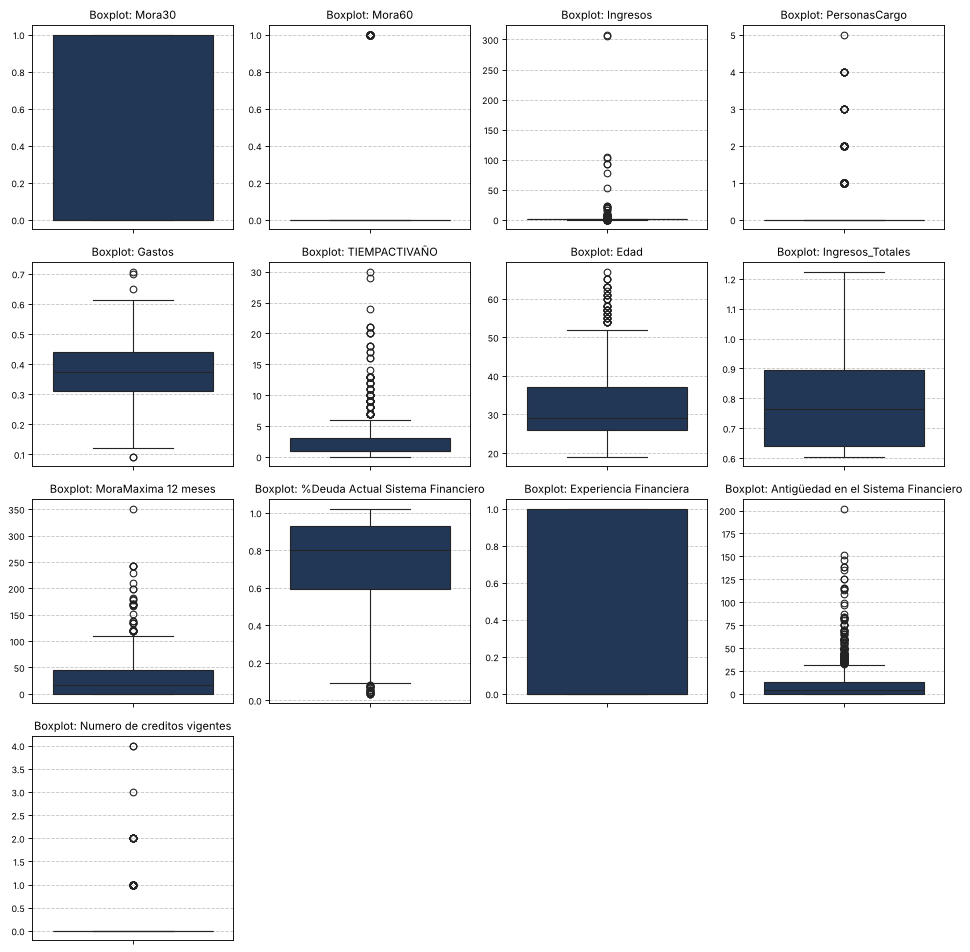

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Seleccionar solo las columnas numéricas
numerical_cols = df.select_dtypes(include=['number']).columns

# Excluir la columna 'Cliente' si es numérica, ya que generalmente es un ID y no se presta para boxplots significativos.
if 'Cliente' in numerical_cols:
    numerical_cols = numerical_cols.drop('Cliente')

# Calcular el número de filas y columnas para la matriz de boxplots
num_plots = len(numerical_cols)
num_cols = 4 # Número deseado de columnas en la cuadrícula
num_rows = int(np.ceil(num_plots / num_cols))

plt.figure(figsize=(num_cols * 3, num_rows * 3)) # Ajustar el tamaño total de la figura

for i, column in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1) # Crear un subplot para cada columna
    sns.boxplot(y=df[column].dropna(), color=paleta_consultora[0])
    plt.title(f'Boxplot: {column}', fontsize=10)
    plt.ylabel('') # Ocultar etiqueta y para no saturar
    plt.tick_params(axis='y', labelsize=8) # Reducir tamaño de ticks
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout() # Ajustar el diseño para evitar superposiciones
plt.show()

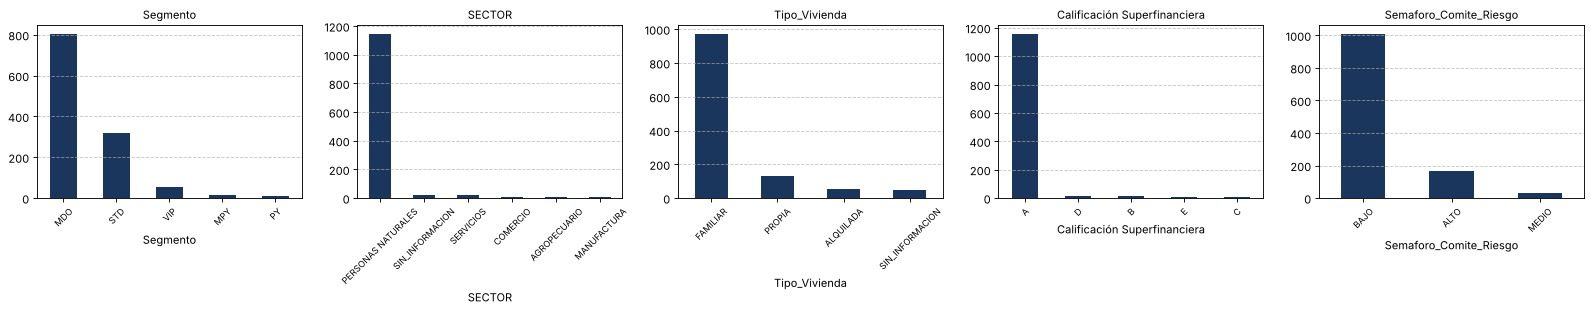

Tasa global de Mora30: 26.3% | Tasa global de Mora60: 11.7%


In [6]:
# Variables categóricas de la base limpia
cols_categoricas = ["Segmento", "SECTOR", "Tipo_Vivienda", "Calificación Superfinanciera", "Semaforo_Comite_Riesgo"]
fig, axes = plt.subplots(1, len(cols_categoricas), figsize=(20, 4))
for ax, col in zip(axes, cols_categoricas):
    df[col].value_counts().plot(kind="bar", ax=ax, color=paleta_consultora[0])
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Tasa global de Mora30: {df['Mora30'].mean():.1%} | Tasa global de Mora60: {df['Mora60'].mean():.1%}")

# 5- Análisis descriptivo

## Tasa de Mora 30 y 60

In [7]:
import pandas as pd

# Asegurarse de que las columnas de mora sean numéricas
df['Mora30'] = pd.to_numeric(df['Mora30'], errors='coerce')
df['Mora60'] = pd.to_numeric(df['Mora60'], errors='coerce')

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Segmento'
mora_por_segmento = df.groupby('Segmento')[['Mora30', 'Mora60']].mean().reset_index()
print("Tasa de Mora por Segmento:")
display(mora_por_segmento)

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Calificación Superfinanciera'
mora_por_calificacion = df.groupby('Calificación Superfinanciera')[['Mora30', 'Mora60']].mean().reset_index()
print("\nTasa de Mora por Calificación Superfinanciera:")
display(mora_por_calificacion)

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Segmento' y 'Calificación Superfinanciera'
mora_segmento_calificacion = df.groupby(['Segmento', 'Calificación Superfinanciera'])[['Mora30', 'Mora60']].mean().reset_index()
print("\nTasa de Mora por Segmento y Calificación Superfinanciera:")
display(mora_segmento_calificacion)

Tasa de Mora por Segmento:


,Segmento,Mora30,Mora60
0,MDO,0.250620,0.115385
1,MPY,0.500000,0.062500
2,PY,0.272727,0.000000
3,STD,0.299065,0.124611
4,VIP,0.166667,0.129630



Tasa de Mora por Calificación Superfinanciera:


,Calificación Superfinanciera,Mora30,Mora60
0,A,0.264021,0.118205
1,B,0.357143,0.214286
2,C,0.111111,0.000000
3,D,0.400000,0.066667
4,E,0.000000,0.000000



Tasa de Mora por Segmento y Calificación Superfinanciera:


,Segmento,Calificación Superfinanciera,Mora30,Mora60
0,MDO,A,0.249680,0.117798
1,MDO,B,0.166667,0.166667
2,MDO,C,0.333333,0.000000
3,MDO,D,0.555556,0.000000
4,MDO,E,0.000000,0.000000
5,MPY,A,0.500000,0.062500
6,PY,A,0.111111,0.000000
7,PY,B,1.000000,0.000000
8,STD,A,0.311037,0.123746
9,STD,B,0.333333,0.333333


## Escenario Probabilisiticos

## Por Calificacion

¿ Cuál es la probabilidad de que un cliente con calificación C, D o E entre en mora,
comparado con uno calificado A o B ?

In [8]:
# Calcular la probabilidad de Mora30 para clientes con calificación A o B
calificaciones_ab = ['A', 'B']
prob_mora_ab = df[df['Calificación Superfinanciera'].isin(calificaciones_ab)]['Mora30'].mean()

# Calcular la probabilidad de Mora30 para clientes con calificación C, D o E
calificaciones_cde = ['C', 'D', 'E']
prob_mora_cde = df[df['Calificación Superfinanciera'].isin(calificaciones_cde)]['Mora30'].mean()

print(f"Probabilidad de Mora30 para clientes con calificación A o B: {prob_mora_ab:.2%}")
print(f"Probabilidad de Mora30 para clientes con calificación C, D o E: {prob_mora_cde:.2%}")

# Comparación
if prob_mora_ab > prob_mora_cde:
    print(f"\nLos clientes con calificación A o B tienen una probabilidad {prob_mora_ab - prob_mora_cde:.2%} mayor de entrar en mora30 que los de calificación C, D o E.")
elif prob_mora_cde > prob_mora_ab:
    print(f"\nLos clientes con calificación C, D o E tienen una probabilidad {prob_mora_cde - prob_mora_ab:.2%} mayor de entrar en mora30 que los de calificación A o B.")
else:
    print("\nLa probabilidad de Mora30 es similar para ambos grupos de calificación.")

Probabilidad de Mora30 para clientes con calificación A o B: 26.51%
Probabilidad de Mora30 para clientes con calificación C, D o E: 20.00%

Los clientes con calificación A o B tienen una probabilidad 6.51% mayor de entrar en mora30 que los de calificación C, D o E.


## Por Experiencia Financiera

¿Qué tan probable es que un cliente sin experiencia financiera previa
(Experiencia_Financiera = 0) caiga en mora, frente a uno que ya tenía historial?

In [9]:
# Asegurarse de que la columna 'Experiencia Financiera' sea numérica
df['Experiencia Financiera'] = pd.to_numeric(df['Experiencia Financiera'], errors='coerce')

# Calcular la probabilidad de Mora30 para clientes sin experiencia financiera (0)
prob_mora_sin_experiencia = df[df['Experiencia Financiera'] == 0]['Mora30'].mean()

# Calcular la probabilidad de Mora30 para clientes con experiencia financiera (1)
prob_mora_con_experiencia = df[df['Experiencia Financiera'] == 1]['Mora30'].mean()

print(f"Probabilidad de Mora30 para clientes SIN experiencia financiera: {prob_mora_sin_experiencia:.2%}")
print(f"Probabilidad de Mora30 para clientes CON experiencia financiera: {prob_mora_con_experiencia:.2%}")

# Comparación
if prob_mora_sin_experiencia > prob_mora_con_experiencia:
    print(f"\nLos clientes SIN experiencia financiera tienen una probabilidad {prob_mora_sin_experiencia - prob_mora_con_experiencia:.2%} mayor de entrar en mora30 que los CON experiencia financiera.")
elif prob_mora_con_experiencia > prob_mora_sin_experiencia:
    print(f"\nLos clientes CON experiencia financiera tienen una probabilidad {prob_mora_con_experiencia - prob_mora_sin_experiencia:.2%} mayor de entrar en mora30 que los SIN experiencia financiera.")
else:
    print("\nLa probabilidad de Mora30 es similar para ambos grupos de experiencia financiera.")

Probabilidad de Mora30 para clientes SIN experiencia financiera: 28.91%
Probabilidad de Mora30 para clientes CON experiencia financiera: 21.39%

Los clientes SIN experiencia financiera tienen una probabilidad 7.52% mayor de entrar en mora30 que los CON experiencia financiera.


## Por Cantidad de Creditos Vigentes

¿Existe relación entre el número de créditos vigentes y la probabilidad de mora?


Probabilidad de Mora30 por Número de Créditos Vigentes:


,Numero de creditos vigentes,Probabilidad_Mora30
0,0,0.265027
1,1,0.241379
2,2,0.300000
3,3,0.000000
4,4,0.000000


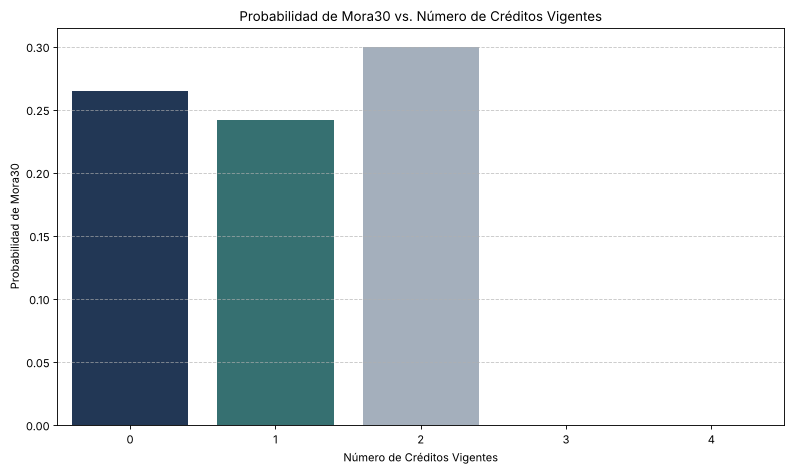

In [10]:
# Calcular la probabilidad de Mora30 para cada número de créditos vigentes
prob_mora_por_creditos = df.groupby('Numero de creditos vigentes')['Mora30'].mean().reset_index()
prob_mora_por_creditos.rename(columns={'Mora30': 'Probabilidad_Mora30'}, inplace=True)

print("Probabilidad de Mora30 por Número de Créditos Vigentes:")
display(prob_mora_por_creditos)

# Definir la paleta de colores de la consultora
paleta_consultora = ['#1A365D', '#2C7A7B', '#A0AEC0', '#4FD1C5']

# Visualizar la relación
plt.figure(figsize=(10, 6))
sns.barplot(x='Numero de creditos vigentes', y='Probabilidad_Mora30', data=prob_mora_por_creditos, hue='Numero de creditos vigentes', palette=paleta_consultora, legend=False)
plt.title('Probabilidad de Mora30 vs. Número de Créditos Vigentes')
plt.xlabel('Número de Créditos Vigentes')
plt.ylabel('Probabilidad de Mora30')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
# Inicio Entrenamiento de Datos

In [11]:
# Definir la variable objetivo y las columnas que deben excluirse
import janitor as jn
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

objetivo = "mora30"
cols_leake = [
    "segmento",
    "sector",
    "regcons",
]
excluir = [
    "cliente",
    "mora30",
    "mora60",
    "fdesem"
] + cols_leake

df = jn.clean_names(df)

x = df.drop(columns=excluir)
y = df[objetivo]

print("Forma de X:", x.shape)
print("Media de y:", y.mean())
print("Conteo de tipos de datos en X:")
print(x.dtypes.value_counts())

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print("Forma de X_train:", x_train.shape)
print("Forma de X_test:", x_test.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de y_test:", y_test.shape)

modelo_tonto = DummyClassifier(strategy="most_frequent")
modelo_tonto.fit(x_train, y_train)
print("Modelo DummyClassifier entrenado correctamente.")

predicciones_tonto = modelo_tonto.predict(x_test)
exactitud_tonto = accuracy_score(y_test, predicciones_tonto)
print("Accuracy del DummyClassifier:", exactitud_tonto)

matriz_confusion_tonto = confusion_matrix(y_test, predicciones_tonto)
print("Matriz de confusión del DummyClassifier:")
print(matriz_confusion_tonto)

Forma de X: (1208, 20)
Media de y: 0.2632450331125828
Conteo de tipos de datos en X:
str        8
int64      7
float64    4
object     1
Name: count, dtype: int64
Forma de X_train: (966, 20)
Forma de X_test: (242, 20)
Forma de y_train: (966,)
Forma de y_test: (242,)
Modelo DummyClassifier entrenado correctamente.
Accuracy del DummyClassifier: 0.7355371900826446
Matriz de confusión del DummyClassifier:
[[178   0]
 [ 64   0]]


---
## K-means

In [12]:
# Seleccionar las variables numéricas disponibles después de aplicar clean_names
columnas_excluidas = {"cliente", "mora30", "mora60"}
variables_numericas = [
    columna
    for columna in df.select_dtypes(include="number").columns
    if columna not in columnas_excluidas
]

X = df[variables_numericas].copy()
print("Variables numéricas seleccionadas:", variables_numericas)
print("Valores nulos por variable:")
print(X.isnull().sum())
display(X.describe().T)

Variables numéricas seleccionadas: ['ingresos', 'personascargo', 'gastos', 'tiempactivano', 'edad', 'ingresos_totales', 'moramaxima_12_meses', '%deuda_actual_sistema_financiero', 'experiencia_financiera', 'antiguedad_en_el_sistema_financiero', 'numero_de_creditos_vigentes']
Valores nulos por variable:
ingresos                               0
personascargo                          0
gastos                                 0
tiempactivano                          0
edad                                   0
ingresos_totales                       0
moramaxima_12_meses                    0
%deuda_actual_sistema_financiero       0
experiencia_financiera                 0
antiguedad_en_el_sistema_financiero    0
numero_de_creditos_vigentes            0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ingresos,1208.0,2.166430,13.970299,0.000000,0.900000,1.142728,1.260000,308.000000
personascargo,1208.0,0.322020,0.708414,0.000000,0.000000,0.000000,0.000000,5.000000
gastos,1208.0,0.387946,0.081910,0.091945,0.310379,0.372309,0.441346,0.707305
tiempactivano,1208.0,2.589404,3.305533,0.000000,1.000000,1.000000,3.000000,30.000000
edad,1208.0,32.392384,9.429194,19.000000,26.000000,29.000000,37.000000,67.000000
ingresos_totales,1208.0,0.786996,0.153785,0.604185,0.640763,0.764836,0.896000,1.224009
moramaxima_12_meses,1208.0,26.130795,36.220778,0.000000,0.000000,17.000000,45.000000,351.000000
%deuda_actual_sistema_financiero,1208.0,0.727615,0.250683,0.034204,0.591707,0.803714,0.928225,1.022126
experiencia_financiera,1208.0,0.344371,0.475359,0.000000,0.000000,0.000000,1.000000,1.000000
antiguedad_en_el_sistema_financiero,1208.0,11.559603,20.664073,0.000000,0.000000,4.000000,13.000000,202.000000


¿Por qué Cliente no está en la lista? ¿Por qué Mora30 tampoco?

Por que la variable cliente puede permitir que genenere grupos por su relacion con los datos. y la mora30 es la variable objetivo, y puede hacer que el modelo se aprenda las respuestas y quede `Sobre Ajustado`

In [13]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()
X_esc = scaler.fit_transform(X)

pd.DataFrame(X_esc, columns=variables_numericas).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ingresos,1208.0,0.0,1.0,-0.16,-0.09,-0.07,-0.06,21.90
personascargo,1208.0,0.0,1.0,-0.45,-0.45,-0.45,-0.45,6.61
gastos,1208.0,0.0,1.0,-3.62,-0.95,-0.19,0.65,3.90
tiempactivano,1208.0,-0.0,1.0,-0.78,-0.48,-0.48,0.12,8.30
edad,1208.0,-0.0,1.0,-1.42,-0.68,-0.36,0.49,3.67
ingresos_totales,1208.0,-0.0,1.0,-1.19,-0.95,-0.14,0.71,2.84
moramaxima_12_meses,1208.0,0.0,1.0,-0.72,-0.72,-0.25,0.52,8.97
%deuda_actual_sistema_financiero,1208.0,0.0,1.0,-2.77,-0.54,0.30,0.80,1.18
experiencia_financiera,1208.0,-0.0,1.0,-0.72,-0.72,-0.72,1.38,1.38
antiguedad_en_el_sistema_financiero,1208.0,0.0,1.0,-0.56,-0.56,-0.37,0.07,9.22


In [14]:
from sklearn.cluster import KMeans

kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
etiquetas3 = kmeans3.fit_predict(X_esc)

pd.Series(etiquetas3).value_counts().sort_index()

0    432
1    101
2    675

In [15]:
centroides = scaler.inverse_transform(kmeans3.cluster_centers_)
tabla_centroides = pd.DataFrame(centroides, columns=variables_numericas).round(1)
tabla_centroides["n_clientes"] = pd.Series(etiquetas3).value_counts().sort_index().values
tabla_centroides

# Cluster 0 - Ingresos bajos con gastas altos
# Cluster 1 - Ingresos medios con gastos moderados y historial crediticio equilibrado
# Cluster 2 - Ingresos altos y mucho historial crediticio


,ingresos,personascargo,gastos,tiempactivano,edad,ingresos_totales,moramaxima_12_meses,%deuda_actual_sistema_financiero,experiencia_financiera,antiguedad_en_el_sistema_financiero,numero_de_creditos_vigentes,n_clientes
0,1.2,0.3,0.5,2.6,32.2,0.9,26.0,0.8,0.4,16.8,0.0,432
1,3.2,0.5,0.4,3.4,35.5,0.8,29.9,0.7,0.8,7.1,1.3,101
2,2.7,0.3,0.3,2.5,32.0,0.7,25.7,0.7,0.3,8.9,0.0,675


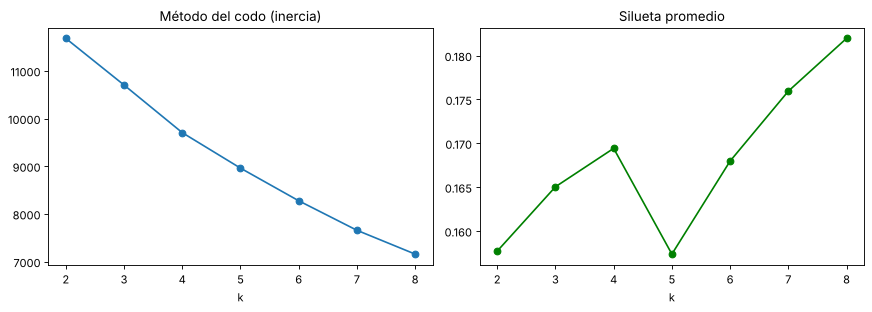

,k,inercia,silueta
0,2,11680.0,0.158
1,3,10702.0,0.165
2,4,9704.0,0.169
3,5,8961.0,0.157
4,6,8277.0,0.168
5,7,7658.0,0.176
6,8,7159.0,0.182


In [16]:
from sklearn.metrics import silhouette_score

inercias, siluetas = [], []
ks = range(2, 9)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labs = km.fit_predict(X_esc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_esc, labs))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inercias, marker="o"); ax[0].set_title("Método del codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, siluetas, marker="o", color="green"); ax[1].set_title("Silueta promedio"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

pd.DataFrame({"k": ks, "inercia": np.round(inercias), "silueta": np.round(siluetas, 3)})

k elegido = K = 4
Segun la silueta, es el valor mas optimo con el menor numero de k y con la mayor puntuacion de silueta.

         n_clientes  tasa_mora30  ...  deuda_prom  tasa_global_mora30
cluster                           ...                                
0               101        0.267  ...       0.748               0.263
1               672        0.260  ...       0.705               0.263
2               433        0.268  ...       0.760               0.263
3                 2        0.000  ...       0.183               0.263

[4 rows x 7 columns]


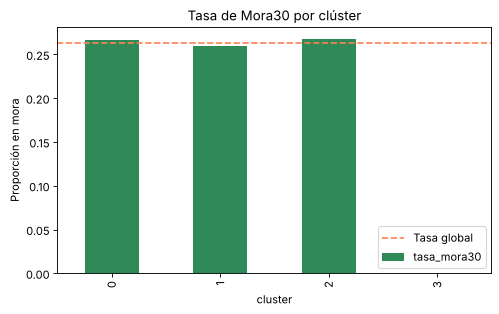

In [17]:
k_final = 4   # <- pongan SU k elegido
km_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
df["cluster"] = km_final.fit_predict(X_esc)

perfil = df.groupby("cluster").agg(
    n_clientes=("cluster", "size"),
    tasa_mora30=("mora30", "mean"),
    tasa_mora60=("mora60", "mean"),
    edad_prom=("edad", "mean"),
    ingresos_prom=("ingresos", "mean"),
    deuda_prom=("%deuda_actual_sistema_financiero", "mean")
).round(3)

perfil["tasa_global_mora30"] = df["mora30"].mean().round(3)
print(perfil)

# Visualización de la tasa de mora30 por clúster

ax = perfil["tasa_mora30"].plot(kind="bar", color="seagreen", figsize=(7, 4))
ax.axhline(df["mora30"].mean(), color="coral", linestyle="--", label="Tasa global")
ax.set_title("Tasa de Mora30 por clúster");
ax.set_ylabel("Proporción en mora");
ax.legend()
plt.show()

## Reporte K-Means 

**¿Qué k eligieron y por qué?**

Se eligio k=4 porque se observó en la silueta que este valor de k proporcionaba una buena separación entre los clústeres en la menor cantidad de clústeres posible.

**¿Cuál es el clúster con mayor tasa de Mora30 y cómo lo describirían en una frase a un gerente de riesgo?**
    
El cluster 2 es el que tiene la mayor tasa de Mora30, estos son los que tienen mas deuda, edad promedio de 32 años y ingresos relativamente bajos.

**¿Cuál es el clúster de menor riesgo y qué lo caracteriza?**

El cluster 1 y son los que tienen menos deuda y mas ingresos promedio.

**¿Qué variable creen que más "dividió" a los clientes? ¿Cómo lo saben?**

El promedio de ingresos junto con la deuda, por que en la agrupacion de los cluster estos fueron los factores que más diferenciaron a los clientes.

**¿Qué pasaría si NO hubieran escalado los datos? (pruébenlo en una celda si les queda tiempo: corran K-means sobre X en vez de X_esc y comparen los tamaños de clúster).**

los datos no escalados pueden llevar a que las variables con mayores magnitudes dominen la formación de los clústeres, resultando en agrupaciones que no reflejan correctamente la estructura subyacente de los datos.

In [18]:
kmeans4 = KMeans(n_clusters=3, random_state=42, n_init=10)
etiquetas_sin_escalado = kmeans4.fit_predict(X)

print(pd.Series(etiquetas_sin_escalado).value_counts().sort_index())

# X no está escalado: los centroides ya están en unidades originales (no se aplica inverse_transform)
centroides = kmeans4.cluster_centers_
tabla_centroides = pd.DataFrame(centroides, columns=variables_numericas).round(1)
tabla_centroides["n_clientes"] = pd.Series(etiquetas_sin_escalado).value_counts().sort_index().values
tabla_centroides

0    893
1    290
2     25
Name: count, dtype: int64


,ingresos,personascargo,gastos,tiempactivano,edad,ingresos_totales,moramaxima_12_meses,%deuda_actual_sistema_financiero,experiencia_financiera,antiguedad_en_el_sistema_financiero,numero_de_creditos_vigentes,n_clientes
0,2.4,0.3,0.4,2.6,32.5,0.8,9.6,0.7,0.4,12.2,0.1,893
1,1.7,0.5,0.4,2.6,32.4,0.8,63.2,0.7,0.3,9.9,0.1,290
2,1.0,0.2,0.4,1.4,28.2,0.7,187.0,0.7,0.4,9.6,0.2,25


---
DBScan

In [19]:
X_num = df[variables_numericas].copy()

print(X_esc.shape)                 # (≈10000, ≈10-11)
print(list(X_num.columns))         # no debe aparecer Cliente, Mora30 ni Mora60
print(np.abs(X_esc.mean().round(2)).max(), X_esc.std().round(2).min())  # ≈ 0 y ≈ 1

(1208, 11)
['ingresos', 'personascargo', 'gastos', 'tiempactivano', 'edad', 'ingresos_totales', 'moramaxima_12_meses', '%deuda_actual_sistema_financiero', 'experiencia_financiera', 'antiguedad_en_el_sistema_financiero', 'numero_de_creditos_vigentes']
0.0 1.0


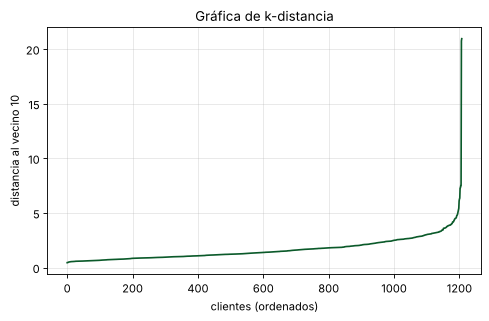

In [20]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

k = 10                                            # = min_samples
nn = NearestNeighbors(n_neighbors=k).fit(X_esc)
dist, _ = nn.kneighbors(X_esc)
kdist = np.sort(dist[:, -1])                      # distancia de cada cliente a su vecino nº k

plt.figure(figsize=(7, 4))
plt.plot(kdist, color="#0B5A2A")
plt.xlabel("clientes (ordenados)")
plt.ylabel(f"distancia al vecino {k}")
plt.title("Gráfica de k-distancia")
plt.grid(alpha=.3)
plt.show()

eps_rodilla = 5

In [21]:
from sklearn.cluster import DBSCAN

def correr_dbscan(eps, min_samples=10):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit(X_esc).labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = (labels == -1).sum()
    print(f"eps={eps:.2f} | {n_clusters} clústeres | {n_ruido} ruido ({100*n_ruido/len(labels):.1f} %)")
    return labels

eps_rodilla = 1.8          # ← reemplacen por SU valor del paso 2
for e in [eps_rodilla*0.8, eps_rodilla, eps_rodilla*1.2]:
    correr_dbscan(e)

labels = correr_dbscan(eps_rodilla)   # nos quedamos con la rodilla

eps=1.44 | 4 clústeres | 443 ruido (36.7 %)
eps=1.80 | 3 clústeres | 293 ruido (24.3 %)
eps=2.16 | 2 clústeres | 186 ruido (15.4 %)
eps=1.80 | 3 clústeres | 293 ruido (24.3 %)


🛠️ Autoevaluación: ¿en qué dirección cambió el número de puntos ruido al subir eps? ¿Por qué?

Cambió en la dirección de disminuir, porque al aumentar eps, más puntos se consideran vecinos y, por lo tanto, menos puntos se clasifican como ruido.

In [22]:
import pandas as pd

# Outliers IQR: 1 si el cliente cae fuera de 1.5·IQR en AL MENOS una variable numérica
Q1, Q3 = X_num.quantile(.25), X_num.quantile(.75)
IQR = Q3 - Q1
fuera = (X_num < Q1 - 1.5*IQR) | (X_num > Q3 + 1.5*IQR)
df["outlier_iqr"]  = fuera.any(axis=1).astype(int)
df["ruido_dbscan"] = (labels == -1).astype(int)

tabla = pd.crosstab(df["ruido_dbscan"], df["outlier_iqr"], margins=True)
print(tabla)

inter = ((df.ruido_dbscan == 1) & (df.outlier_iqr == 1)).sum()
union = ((df.ruido_dbscan == 1) | (df.outlier_iqr == 1)).sum()
print("Índice de Jaccard:", round(inter / union, 2))

outlier_iqr     0    1   All
ruido_dbscan                
0             588  327   915
1              16  277   293
All           604  604  1208
Índice de Jaccard: 0.45


In [23]:
df.loc[[1, 0], X_num.columns]

,ingresos,personascargo,gastos,tiempactivano,edad,ingresos_totales,moramaxima_12_meses,%deuda_actual_sistema_financiero,experiencia_financiera,antiguedad_en_el_sistema_financiero,numero_de_creditos_vigentes
1,1.20,1,0.3080,2,36,0.6160,0,0.351257,1,5,0
0,1.28,0,0.4097,1,26,0.8194,47,0.282593,1,20,0


🛠️ Autoevaluación: tomen 3 clientes de la celda (1, 0) y mírenlos con df.loc[..., X_num.columns]. ¿Pueden decir en una frase por qué "no se parecen a nadie"?

Por ingresos bajos y pocas personas a cargo


In [24]:
df["cluster_db"] = labels

perfil = df.groupby("cluster_db")[["mora30", "mora60"]].mean().round(3)
perfil["n"] = df["cluster_db"].value_counts()
perfil["%"] = (100 * perfil["n"] / len(df)).round(1)
print(perfil)                                        # la fila -1 es el ruido

print("Tasa global Mora30:", round(df["mora30"].mean(), 3))
print("Mora30 en ruido:   ", round(df.loc[df.ruido_dbscan == 1, "mora30"].mean(), 3))
print("Mora30 en IQR:     ", round(df.loc[df.outlier_iqr == 1, "mora30"].mean(), 3))
print("Mora30 en ambos:   ", round(df.loc[(df.ruido_dbscan == 1) & (df.outlier_iqr == 1), "mora30"].mean(), 3))

            mora30  mora60    n     %
cluster_db                           
-1           0.420   0.218  293  24.3
 0           0.165   0.035  255  21.1
 1           0.234   0.108  628  52.0
 2           0.188   0.000   32   2.6
Tasa global Mora30: 0.263
Mora30 en ruido:    0.42
Mora30 en IQR:      0.308
Mora30 en ambos:    0.415


* ¿Cuántos clústeres encontró DBSCAN y qué porcentaje de clientes quedó como ruido? ¿Cómo cambió al mover eps? 

Con eps = 1.80, DBSCAN encontró 3 clústeres y clasificó 293 clientes como ruido, equivalentes al 24,3 % de la cartera.
Al mover eps, puede aumentar o disminuir el número de clústeres y la cantidad de clientes clasificados como ruido.

* ¿Qué le dice eso al banco sobre la estructura de su cartera?

Que tiene una tasa de mora30 aproximada del 24% con sus clientes

* ¿Qué tan parecidas son las listas de IQR y de ruido DBSCAN? (Jaccard + una explicación de las celdas de la tabla cruzada.) ¿Qué clientes marcaría para revisión manual y por qué?

 Jaccard fue 0,45, lo que indica que hay una superposición moderada entre los clientes identificados como outliers por IQR y los clasificados como ruido por DBSCAN.
 los 277 clientes detectados por ambos métodos, porque presentan simultáneamente valores extremos en alguna variable y baja cercanía con otros clientes.


* ¿Los clientes "ruido" tienen más o menos Mora30 que el promedio? Con base en eso, propongan una acción concreta de política de crédito (por ejemplo: verificación adicional de datos antes de aprobar, cupo inicial reducido, o simplemente "no hacer nada porque no hay diferencia").

Los clientes clasificados como ruido tienen una tasa de Mora30 de 42,0 %, mientras que la tasa global es de 26,3 %. Por tanto, el grupo ruido presenta una mora aproximadamente 15,7 puntos porcentuales superior al promedio.

**Accion correctiva**: Implementar una verificación adicional de información financiera. Esta revisión podría incluir validación de ingresos, gastos, nivel de endeudamiento y experiencia financiera. No se recomienda rechazar automáticamente estos clientes, pero sí considerar un cupo inicial reducido o condiciones de aprobación más conservadoras.

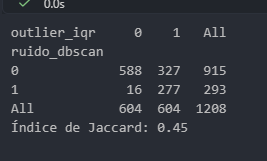
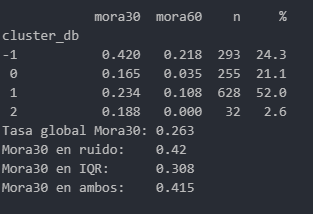


---
# Silueta - Defincion de K

### Variables para el clustering final

Respecto a la primera versión de esta sección se hicieron tres correcciones:
- **Columnas prohibidas:** además de `cliente`, `mora30` y `mora60`, se excluyen `moramaxima_12_meses` (define la mora: `mora30 = 1` exactamente cuando supera 30 días) y las columnas creadas en las secciones anteriores (`cluster`, `outlier_iqr`, `ruido_dbscan`, `cluster_db`), que antes se estaban usando por error para agrupar.
- **Recorte de extremos (percentiles 1 y 99):** hay clientes con ingresos de ~305 cuando la mediana es 1,1; sin el recorte, K-means les dedica un clúster entero a 2 personas.
- **Se quitan variables casi binarias** (`experiencia_financiera`, `numero_de_creditos_vigentes`, `personascargo`): toman solo 2–5 valores y parten los grupos por "tiene / no tiene" en lugar de por perfil financiero.

Con estos cambios la silueta pasa de ≈0,17 a ≈0,25–0,28.

In [25]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

# Columnas que NO deben usarse para agrupar
PROHIBIDAS = ["cliente", "mora30", "mora60",
              "moramaxima_12_meses",                                   # define la mora (fuga)
              "cluster", "outlier_iqr", "ruido_dbscan", "cluster_db"]  # resultados de celdas anteriores
num = df.select_dtypes(include="number").drop(columns=PROHIBIDAS, errors="ignore")

# Recortar extremos (percentil 1 y 99) en las variables continuas
for c in num.columns:
    if num[c].nunique() > 10:
        num[c] = num[c].clip(num[c].quantile(0.01), num[c].quantile(0.99))

# Quitar variables casi binarias, que parten los grupos de forma artificial
num = num.drop(columns=["experiencia_financiera", "numero_de_creditos_vigentes", "personascargo"])

assert not set(PROHIBIDAS) & set(num.columns), "¡Leakage! Quiten las columnas prohibidas de X"

X_esc = StandardScaler().fit_transform(num)
print("X_esc:", X_esc.shape, "| columnas usadas:", list(num.columns))

X_esc: (1208, 7) | columnas usadas: ['ingresos', 'gastos', 'tiempactivano', 'edad', 'ingresos_totales', '%deuda_actual_sistema_financiero', 'antiguedad_en_el_sistema_financiero']


   k  silueta  davies_bouldin  calinski_harabasz   inercia
0  2    0.233           1.729            289.775  6817.828
1  3    0.255           1.296            284.608  5743.133
2  4    0.251           1.390            282.363  4963.717
3  5    0.278           1.123            293.793  4277.474
4  6    0.254           1.159            305.055  3726.839
5  7    0.261           1.084            310.823  3312.416
6  8    0.220           1.143            305.617  3038.704


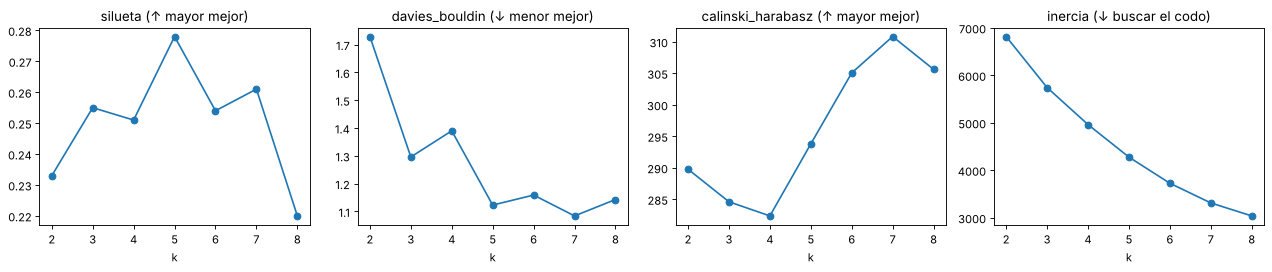

In [26]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_esc), size=min(3000, len(X_esc)), replace=False)  # muestra para la silueta

filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_esc)
    lab = km.labels_
    filas.append({
        "k": k,
        "silueta":  silhouette_score(X_esc[idx], lab[idx]),
        "davies_bouldin": davies_bouldin_score(X_esc, lab),
        "calinski_harabasz": calinski_harabasz_score(X_esc, lab),
        "inercia": km.inertia_,
    })
tabla = pd.DataFrame(filas).round(3)
print(tabla)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, col, regla in zip(ax, ["silueta", "davies_bouldin", "calinski_harabasz", "inercia"],
                         ["↑ mayor mejor", "↓ menor mejor", "↑ mayor mejor", "↓ buscar el codo"]):
    a.plot(tabla["k"], tabla[col], marker="o"); a.set_title(f"{col} ({regla})"); a.set_xlabel("k")
plt.tight_layout(); plt.show()

**¿Qué k propone cada juez?**

| Juez | Regla | k propuesto |
|---|---|---|
| Silueta | mayor es mejor | **k = 5** (0,278) |
| Davies-Bouldin | menor es mejor | **k = 7** (1,084) |
| Calinski-Harabasz | mayor es mejor | **k = 7** (310,8) |
| Inercia (codo) | donde la curva se dobla | **k = 3** (la caída más grande es de 2 a 3) |

**¿Coinciden?** No. k = 7 tiene más votos (2 jueces); k = 5 gana la silueta y queda segundo en Davies-Bouldin (1,123, muy cerca del mínimo).

**Candidatos:** k = 7 (el de más votos) y k = 5 (el que el negocio preferiría: menos segmentos, más fáciles de gestionar por el área de riesgo, y la mejor silueta).

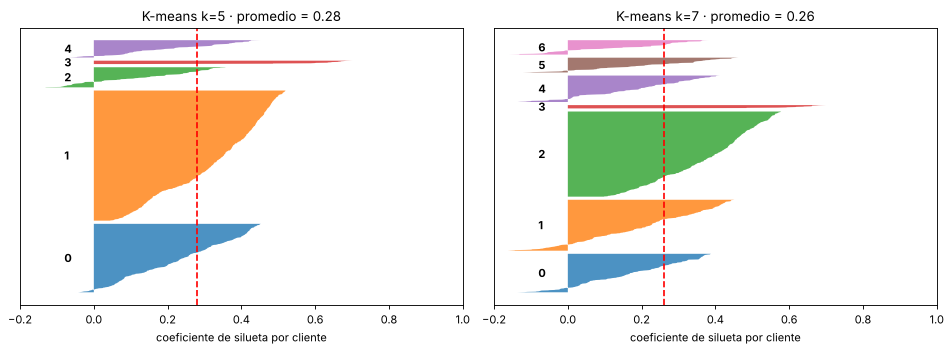

In [27]:
def grafica_silueta(X, labels, ax, titulo):
    sv = silhouette_samples(X, labels); prom = sv.mean(); y0 = 10
    for c in np.unique(labels):
        v = np.sort(sv[labels == c]); n = len(v)
        ax.fill_betweenx(np.arange(y0, y0 + n), 0, v, alpha=.8)
        ax.text(-0.08, y0 + n / 2, str(c), va="center", fontweight="bold")
        y0 += n + 15
    ax.axvline(prom, color="red", ls="--"); ax.set_yticks([]); ax.set_xlim(-0.2, 1)
    ax.set_title(f"{titulo} · promedio = {prom:.2f}"); ax.set_xlabel("coeficiente de silueta por cliente")

K_CANDIDATOS = [5, 7]   # k=5: gana la silueta | k=7: gana Davies-Bouldin y Calinski-Harabasz
fig, ax = plt.subplots(1, len(K_CANDIDATOS), figsize=(6 * len(K_CANDIDATOS), 4.5))
for a, k in zip(np.atleast_1d(ax), K_CANDIDATOS):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_esc)
    grafica_silueta(X_esc[idx], lab[idx], a, f"K-means k={k}")
plt.tight_layout(); plt.show()

Checklist de las 4 señales de alarma:

| Señal de alarma | k = 5 | k = 7 |
|---|---|---|
| Un clúster entero por debajo de la línea del promedio | No (el clúster 2 queda casi todo por debajo, pero no entero) | No |
| Cuchillos de tamaños muy distintos (uno gigante, varios diminutos) | **Sí**: 655 clientes vs 18 | **Sí**: un clúster grande y uno diminuto (el de ingresos altos) |
| Muchos valores negativos visibles | Pocos, concentrados en el clúster 2 | Algunos, en los clústeres 0 y 1 |
| Promedio muy alto solo porque k = 2 | No aplica | No aplica |

Los tamaños distintos no son un error del modelo: la cartera está concentrada en un perfil mayoritario (personas naturales jóvenes, ingresos cercanos a 1, sin créditos vigentes) y unos pocos clientes son muy diferentes.

In [28]:
EPS, MIN_S = 0.8, 10          # con eps >= 1.0 DBSCAN encuentra un solo clúster en estas variables
lab_db = DBSCAN(eps=EPS, min_samples=MIN_S).fit_predict(X_esc)

ruido = (lab_db == -1).mean()
n_cl = len(set(lab_db)) - (1 if -1 in lab_db else 0)
print(f"DBSCAN: {n_cl} clústeres | ruido = {ruido:.1%}")

m = lab_db != -1
if n_cl >= 2:
    print("silueta DBSCAN (sin ruido):", round(silhouette_score(X_esc[m], lab_db[m], sample_size=3000, random_state=42), 3))
    print("davies_bouldin DBSCAN (sin ruido):", round(davies_bouldin_score(X_esc[m], lab_db[m]), 3))
else:
    print("DBSCAN no separó ≥ 2 clústeres: no se puede calcular silueta")

DBSCAN: 2 clústeres | ruido = 40.5%
silueta DBSCAN (sin ruido): 0.251
davies_bouldin DBSCAN (sin ruido): 0.94


**DBSCAN con estas variables:** con `eps = 0.8` encuentra 2 clústeres y deja el 40,5 % de los clientes como ruido (silueta sin ruido 0,25). Con `eps ≥ 1.0` todo queda en un solo clúster. La cartera es una sola masa densa sin grupos separados por "vacíos", por eso DBSCAN no sirve para segmentarla y se trabaja con K-means, que asigna al 100 % de los clientes con una silueta similar (0,28).

In [29]:
def estabilidad(k, semillas=range(5)):
    labs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X_esc) for s in semillas]
    aris = [adjusted_rand_score(labs[0], l) for l in labs[1:]]
    return np.mean(aris), np.min(aris)

for k in K_CANDIDATOS:
    prom, peor = estabilidad(k)
    print(f"k={k}: ARI promedio = {prom:.3f} | peor corrida = {peor:.3f}")

k=5: ARI promedio = 0.651 | peor corrida = 0.394
k=7: ARI promedio = 0.849 | peor corrida = 0.575


**Estabilidad (ARI entre corridas con distintas semillas):** k = 7 es más estable (ARI promedio 0,85; peor 0,58) que k = 5 (0,65; peor 0,39). Es decir, con k = 5 algunos clientes cambian de segmento según la semilla inicial. Se mitiga entrenando el modelo final con `n_init=10` y `random_state=42`, que deja siempre la misma solución.

In [30]:
K_FINAL = 5   # <- decisión del equipo, justificada abajo
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X_esc)
df["cluster"] = km.labels_

# Perfil post hoc (AQUÍ sí se usa Mora30, solo para describir, nunca para agrupar)
perfil = df.groupby("cluster").agg(
    clientes=("cluster", "size"),
    tasa_mora30=("mora30", "mean"),
    ingreso_mediano=("ingresos", "median"),
    edad_media=("edad", "mean"),
    deuda_media=("%deuda_actual_sistema_financiero", "mean"),
).round(3)
print(perfil)

# df.to_csv("equipo_XX_base_credito_limpia_cluster.csv", index=False)

         clientes  tasa_mora30  ingreso_mediano  edad_media  deuda_media
cluster                                                                 
0             345        0.258            1.098      31.742        0.759
1             655        0.270            1.141      31.127        0.718
2             102        0.265            1.106      39.676        0.668
3              18        0.111           23.319      33.444        0.562
4              88        0.261            1.200      35.705        0.777


In [31]:
from scipy.stats import chi2_contingency

# Perfil completo de cada segmento (medianas de las variables usadas para agrupar)
perfil_completo = num.assign(cluster=df["cluster"].values).groupby("cluster").median().round(2)
perfil_completo["clientes"] = df["cluster"].value_counts().sort_index()
perfil_completo["tasa_mora30"] = df.groupby("cluster")["mora30"].mean().round(3)
perfil_completo["tasa_mora60"] = df.groupby("cluster")["mora60"].mean().round(3)
display(perfil_completo.T)

# ¿La tasa de Mora30 cambia entre segmentos?
_, p_valor, _, _ = chi2_contingency(pd.crosstab(df["cluster"], df["mora30"]))
print(f"Prueba chi-cuadrado Mora30 vs segmento: p = {p_valor:.3f}",
      "(sin diferencia significativa)" if p_valor > 0.05 else "(diferencia significativa)")

cluster,0,1,2,3,4
ingresos,1.100,1.140,1.110,19.490,1.200
gastos,0.480,0.330,0.350,0.310,0.400
tiempactivano,1.000,1.000,10.000,1.000,1.500
edad,29.000,29.000,38.000,30.500,33.000
ingresos_totales,0.950,0.680,0.720,0.620,0.830
%deuda_actual_sistema_financiero,0.850,0.790,0.710,0.490,0.840
antiguedad_en_el_sistema_financiero,3.000,3.000,9.000,1.000,59.000
clientes,345.000,655.000,102.000,18.000,88.000
tasa_mora30,0.258,0.270,0.265,0.111,0.261
tasa_mora60,0.136,0.113,0.078,0.000,0.136


Prueba chi-cuadrado Mora30 vs segmento: p = 0.669 (sin diferencia significativa)


**Nombre de cada segmento (k = 5):**

| Clúster | Clientes | Mora30 | Mora60 | Nombre para el gerente de riesgo |
|---|---|---|---|---|
| 0 | 345 | 25,8 % | 13,6 % | Jóvenes con gastos y deuda altos |
| 1 | 655 | 27,0 % | 11,3 % | Cliente típico: joven, gastos bajos y poca trayectoria laboral |
| 2 | 102 | 26,5 % | 7,8 % | Adultos con trayectoria laboral estable (≈10 años activos) |
| 3 | 18 | 11,1 % | 0,0 % | Ingresos muy altos y poca deuda: el segmento de menor riesgo |
| 4 | 88 | 26,1 % | 13,6 % | Veteranos del sistema financiero (antigüedad ≈59), muy endeudados |

**Lectura:** los segmentos se diferencian claramente en su perfil financiero, pero no en la tasa de Mora30: salvo el segmento de ingresos altos, todos están entre 26 % y 27 % (prueba chi-cuadrado p ≈ 0,67, sin diferencia significativa). Donde sí hay diferencia es en la mora grave: los segmentos 0 y 4 tienen casi el doble de Mora60 (13,6 %) que el segmento 2 (7,8 %).

| Elemento | Qué deben dejar escrito |
|---|---|
| k definitivo | El número **y** una razón métrica (silueta / gráfica / estabilidad) **y** una razón de negocio |
| Nombre de cada segmento | Una frase que un gerente de riesgo entienda (ej. "jóvenes sin historial, mora alta") |
| Jueces en desacuerdo | Si los jueces no coincidieron, cómo desempataron |
| Advertencia | Que `cluster` se calculó sin Cliente/Mora30/Mora60 y por eso puede usarse como variable en la Unidad 3 |

**Mi k definitivo es 5** porque tiene la silueta más alta de todos los k probados (0,278) y el segundo mejor Davies-Bouldin (1,12), y porque 5 segmentos son manejables para el área de riesgo y cada uno tiene un perfil fácil de describir (ver tabla de nombres).

**Jueces en desacuerdo:** la silueta eligió k = 5, Davies-Bouldin y Calinski-Harabasz eligieron k = 7 y el codo k = 3. Desempatamos con la silueta, que mide qué tan bien queda cada cliente en su grupo, y con el criterio de negocio: k = 7 agrega dos segmentos más sin mejorar la silueta (0,26 vs 0,28), y k = 3 deja menos segmentos de los que el negocio necesita para diferenciar perfiles. La desventaja de k = 5 es su menor estabilidad (ARI 0,65), que se controla fijando la semilla.

**Advertencia:** la columna `cluster` se calculó **sin** `Cliente`, `Mora30`, `Mora60` ni `MoraMaxima 12 meses`, por eso puede usarse como variable en la Unidad 3 sin fuga de información. Sin embargo, como la Mora30 casi no cambia entre segmentos, se espera que aporte poco para predecirla; es más útil para describir la cartera y diferenciar la mora grave (Mora60).

---
# Proyecto Final · Modelo simple vs Random Forest

**Objetivo:** con la base ya limpia (secciones 3 y 4), entrenar dos modelos que predigan la mora de los clientes de Bancolombia, compararlos con métricas y concluir cuál conviene usar.

## 1. Planteamiento: qué predecir y con qué modelo

**Variable a predecir:** `mora30` (1 = el cliente cayó en mora de 30 días, 0 = no cayó).

**¿Por qué es importante para la empresa?** El objetivo de Bancolombia para el Q4 de 2026 es identificar a los clientes propensos a caer en mora (sección 1). `mora30` es la primera señal de deterioro de la cartera: detectarla a tiempo permite actuar antes de que el cliente llegue a Mora60 (cobranza preventiva, ajuste de cupo, mayores provisiones). Además, todo cliente con `mora60 = 1` también tiene `mora30 = 1` (política P6), así que `mora30` cubre ambos casos y tiene más ejemplos positivos (≈26 % de los clientes) que `mora60` (≈11 %), lo que facilita el aprendizaje del modelo.

**Tipo de variable y modelos:** es una categoría sí/no, por lo tanto:
- Modelo simple: **Regresión logística** (`LogisticRegression`).
- Modelo complejo: **Random Forest** (`RandomForestClassifier`, `n_estimators=200`, `random_state=42`).

## 2. Preparación de los datos

### 2.1 Verificación de fuga de información

Antes de entrenar se revisa si alguna columna "contiene" la respuesta. Si una variable define a `mora30`, el modelo acertaría casi el 100 % en el papel pero no serviría para anticipar nada en la vida real.

In [32]:
mm = df["moramaxima_12_meses"]
print("¿mora30 == (moramaxima_12_meses > 30)?", f"{((mm > 30).astype(int) == df['mora30']).mean():.1%} de coincidencia")
print("¿mora60 == (moramaxima_12_meses > 60)?", f"{((mm > 60).astype(int) == df['mora60']).mean():.1%} de coincidencia")

print("\nSemáforo del comité vs. mora:")
display(df.groupby("semaforo_comite_riesgo").agg(
    clientes=("mora30", "size"),
    tasa_mora30=("mora30", "mean"),
    moramaxima_prom=("moramaxima_12_meses", "mean"),
    deuda_prom=("%deuda_actual_sistema_financiero", "mean"),
    score_prom=("calificacionsistema_financiero", lambda s: pd.to_numeric(s, errors="coerce").mean()),
).round(3))

¿mora30 == (moramaxima_12_meses > 30)? 100.0% de coincidencia
¿mora60 == (moramaxima_12_meses > 60)? 100.0% de coincidencia

Semáforo del comité vs. mora:


,clientes,tasa_mora30,moramaxima_prom,deuda_prom,score_prom
semaforo_comite_riesgo,,,,,
ALTO,164,0.799,84.372,0.708,746.558
BAJO,1011,0.172,16.465,0.732,732.570
MEDIO,33,0.394,32.818,0.688,764.062


**Resultado:**
- `moramaxima_12_meses` **define** la variable objetivo: `mora30 = 1` exactamente cuando la mora máxima supera 30 días (100 % de coincidencia), y `mora60` cuando supera 60. Es la misma información que se quiere predecir, por lo tanto **se excluye**.
- `semaforo_comite_riesgo` también se excluye: los clientes en ALTO tienen en promedio 84 días de mora máxima frente a 16 de los clientes en BAJO, mientras que su deuda y su score son prácticamente iguales. Esto indica que el semáforo se asigna mirando la mora ya ocurrida, no información disponible antes de que el cliente caiga en mora.

### 2.2 Limpieza para el modelo

Se parte de `df` ya limpio (reglas R1–R8 y P9). Decisiones:
- **Se quitan columnas de código (id) y fugas de información:** `cliente` es un identificador; `mora60` es otra forma de la respuesta (si es 1, `mora30` también es 1); `moramaxima_12_meses` y `semaforo_comite_riesgo` por lo explicado arriba; `fdesem` es una fecha convertida en texto con cientos de valores distintos.
- **`calificacionsistema_financiero`** es un puntaje numérico (score entre 94 y 961) pero viene como texto porque 10 registros traen un punto (".") en lugar del valor. Se convierte a número y esos registros quedan como nulos.
- **Se mantienen fuera** `segmento`, `sector` y `regcons`, igual que en la línea base del taller (celda del `DummyClassifier`), para que la comparación sea coherente.
- **Se quitan las columnas creadas en el clustering** (`cluster`, `outlier_iqr`, `ruido_dbscan`, `cluster_db`) para que los modelos usen solo información original del cliente.
- **Textos con demasiados valores distintos** (más de 20 categorías) se eliminan automáticamente.
- **Nulos:** se eliminan las filas que aún tengan algún valor faltante.
- **Registros gemelos (extensión de la regla R2):** al revisar la base se encontró que cerca del 59 % de los registros vienen en grupos de 2 a 6 "gemelos": misma edad, score, antigüedad, tiempo activo y mismas categorías, con ingresos, gastos y deuda que solo cambian menos de 1 %, y siempre con el mismo valor de `mora30`. Son el mismo cliente repetido. Si se dejan, la separación al azar pone a un gemelo en entrenamiento y al otro en prueba, y el modelo "acierta" porque ya vio la respuesta (el Random Forest llegaba a 90 % de exactitud por esta razón). Se deja **un solo registro por cliente**, igual que en R2.
- Las columnas de texto se convierten a números con `pd.get_dummies`.
- Separación **80 % entrenamiento / 20 % prueba** con `random_state=42` (estratificada para conservar la proporción de mora). Ambos modelos usan exactamente la misma separación.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

datos = df.copy()
objetivo = "mora30"

# El score del sistema financiero es numérico; los "." pasan a nulo
datos["calificacionsistema_financiero"] = pd.to_numeric(
    datos["calificacionsistema_financiero"], errors="coerce"
)

# Columnas que no deben entrar al modelo
cols_id_y_fuga = ["cliente", "mora60", "fdesem", "moramaxima_12_meses", "semaforo_comite_riesgo"]
cols_excluidas_equipo = ["segmento", "sector", "regcons"]
cols_derivadas_clustering = ["cluster", "outlier_iqr", "ruido_dbscan", "cluster_db"]

excluir = [c for c in cols_id_y_fuga + cols_excluidas_equipo + cols_derivadas_clustering
           if c in datos.columns]
datos = datos.drop(columns=excluir)
print("Columnas excluidas:", excluir)

# Textos con demasiados valores distintos
LIMITE_CATEGORIAS = 20
cols_texto = datos.drop(columns=[objetivo]).select_dtypes(exclude="number").columns
cardinalidad = datos[cols_texto].nunique().sort_values(ascending=False)
print("\nValores distintos por columna de texto:")
print(cardinalidad)

cols_alta_card = cardinalidad[cardinalidad > LIMITE_CATEGORIAS].index.tolist()
datos = datos.drop(columns=cols_alta_card)
print("\nColumnas de texto eliminadas por alta cardinalidad:", cols_alta_card)

# Nulos
filas_antes = len(datos)
print("\nNulos por columna (solo las que tienen):")
print(datos.isna().sum()[lambda s: s > 0])
datos = datos.dropna()
print(f"Filas eliminadas por nulos: {filas_antes - len(datos)} | filas finales: {len(datos)}")

# Registros "gemelos": mismo cliente repetido con variaciones < 1 % en ingresos, gastos y deuda
cols_continuas = ["ingresos", "gastos", "ingresos_totales", "%deuda_actual_sistema_financiero"]
cols_clave = [c for c in datos.columns if c not in cols_continuas + [objetivo]]
grupo = datos.groupby(cols_clave, dropna=False).ngroup()
tam_grupo = grupo.map(grupo.value_counts())
print(f"\nRegistros que pertenecen a un grupo de gemelos: {(tam_grupo > 1).sum()} de {len(datos)}")
print(f"Grupos con etiqueta mora30 distinta entre gemelos: {(datos.groupby(grupo)[objetivo].nunique() > 1).sum()}")

datos = datos[~grupo.duplicated(keep="first")].copy()
print(f"Registros después de dejar un solo registro por cliente: {len(datos)}")

# Variables predictoras (X) y objetivo (y)
X = pd.get_dummies(datos.drop(columns=[objetivo]), drop_first=True, dtype=int)
y = datos[objetivo].astype(int)

print("\nForma de X después de get_dummies:", X.shape)
print("Proporción de mora30 en y:", round(y.mean(), 3))

# Separación 80/20 (la misma para los dos modelos)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Columnas excluidas: ['cliente', 'mora60', 'fdesem', 'moramaxima_12_meses', 'semaforo_comite_riesgo', 'segmento', 'sector', 'regcons', 'cluster', 'outlier_iqr', 'ruido_dbscan', 'cluster_db']

Valores distintos por columna de texto:
tipcontrato                     6
estado_civil                    5
nivel_academico                 5
calificacion_superfinanciera    5
tipo_vivienda                   4
ocupacion                       2
genero                          2
dtype: int64

Columnas de texto eliminadas por alta cardinalidad: []

Nulos por columna (solo las que tienen):
calificacionsistema_financiero    11
dtype: int64
Filas eliminadas por nulos: 11 | filas finales: 1197

Registros que pertenecen a un grupo de gemelos: 709 de 1197
Grupos con etiqueta mora30 distinta entre gemelos: 1
Registros después de dejar un solo registro por cliente: 790

Forma de X después de get_dummies: (790, 33)
Proporción de mora30 en y: 0.246
X_train: (632, 33) | X_test: (158, 33)


### Línea base

Un modelo "tonto" que diga siempre la clase más común (*nadie cae en mora*) acierta en esta proporción de casos. Cualquier modelo útil debe superarla.

In [34]:
linea_base = y.value_counts(normalize=True).max()
clase_mas_comun = y.value_counts().idxmax()
print(f"Clase más común: {clase_mas_comun} (0 = no mora)")
print(f"Exactitud de la línea base (decir siempre {clase_mas_comun}): {linea_base:.3f}")

Clase más común: 0 (0 = no mora)
Exactitud de la línea base (decir siempre 0): 0.754


## 3. Entrenamiento de los modelos

### 3.1 Modelo simple: Regresión logística

La regresión logística es sensible a la escala de las variables (por ejemplo, `ingresos` tiene valores atípicos muy grandes frente a variables entre 0 y 1). Por eso se usa un `Pipeline` que primero estandariza con `StandardScaler` (ajustado **solo** con los datos de entrenamiento) y luego entrena el modelo.

In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_simple = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
modelo_simple.fit(X_train, y_train)

pred_simple = modelo_simple.predict(X_test)
proba_simple = modelo_simple.predict_proba(X_test)[:, 1]
print("Regresión logística entrenada.")

Regresión logística entrenada.


**Lectura de la regresión logística:** sus coeficientes indican la dirección del efecto. Un coeficiente positivo aumenta la probabilidad de mora y uno negativo la reduce (como las variables están estandarizadas, se pueden comparar entre sí).

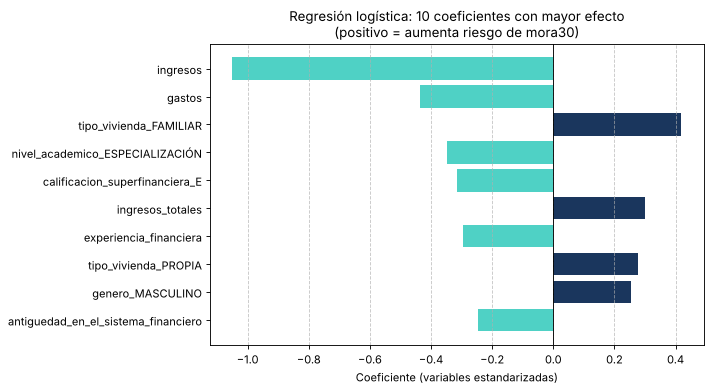

ingresos                              -1.050
gastos                                -0.437
tipo_vivienda_FAMILIAR                 0.419
nivel_academico_ESPECIALIZACIÓN       -0.349
calificacion_superfinanciera_E        -0.316
ingresos_totales                       0.298
experiencia_financiera                -0.295
tipo_vivienda_PROPIA                   0.277
genero_MASCULINO                       0.253
antiguedad_en_el_sistema_financiero   -0.246
dtype: float64


In [36]:
coeficientes = pd.Series(
    modelo_simple.named_steps["logisticregression"].coef_[0],
    index=X.columns,
)
top_coef = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10)

colores = [paleta_consultora[0] if v > 0 else paleta_consultora[3] for v in top_coef]
plt.figure(figsize=(9, 5))
plt.barh(top_coef.index[::-1], top_coef.values[::-1], color=colores[::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Regresión logística: 10 coeficientes con mayor efecto\n(positivo = aumenta riesgo de mora30)")
plt.xlabel("Coeficiente (variables estandarizadas)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print(top_coef.round(3))

### 3.2 Random Forest

Conjunto de 200 árboles de decisión (`n_estimators=200`, `random_state=42`). No necesita escalar las variables.

In [37]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
proba_rf = modelo_rf.predict_proba(X_test)[:, 1]
print("Random Forest entrenado.")

Random Forest entrenado.


### 3.3 Importancia de variables del Random Forest (top 10)

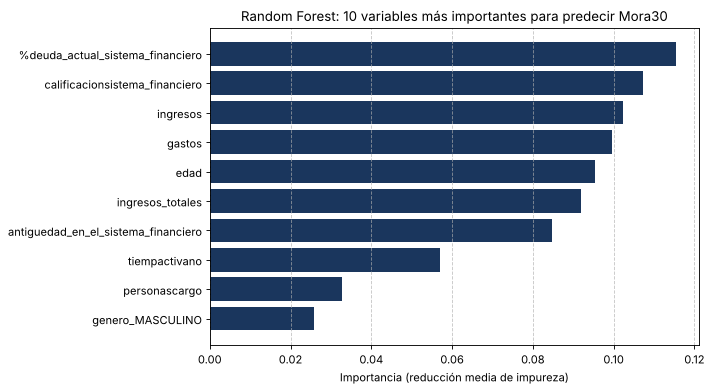

%deuda_actual_sistema_financiero       11.5 %
calificacionsistema_financiero         10.7 %
ingresos                               10.2 %
gastos                                 10.0 %
edad                                    9.5 %
ingresos_totales                        9.2 %
antiguedad_en_el_sistema_financiero     8.5 %
tiempactivano                           5.7 %
personascargo                           3.3 %
genero_MASCULINO                        2.6 %
dtype: str


In [38]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = importancias.head(10)

plt.figure(figsize=(9, 5))
plt.barh(top10.index[::-1], top10.values[::-1], color=paleta_consultora[0])
plt.title("Random Forest: 10 variables más importantes para predecir Mora30")
plt.xlabel("Importancia (reducción media de impureza)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print((top10 * 100).round(1).astype(str) + " %")

## 4. Comparación de los modelos con métricas

Métricas calculadas sobre los **datos de prueba** (20 %):
- **Exactitud:** % de clientes bien clasificados.
- **Precisión:** de los clientes que el modelo marca como "mora", cuántos realmente cayeron en mora.
- **Recall (sensibilidad):** de los clientes que realmente cayeron en mora, cuántos detectó el modelo. Es la métrica más importante para el banco, porque un moroso no detectado es dinero perdido.
- **F1:** equilibrio entre precisión y recall.
- **AUC (complementaria):** capacidad del modelo para ordenar a los clientes de mayor a menor riesgo (0,5 = azar, 1 = perfecto).

In [39]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def evaluar(nombre, y_real, y_pred, y_proba=None):
    return {
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_real, y_pred),
        "Precisión": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1": f1_score(y_real, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_real, y_proba) if y_proba is not None else 0.5,
    }

pred_base = np.full(len(y_test), clase_mas_comun)

tabla_metricas = pd.DataFrame([
    evaluar("Línea base (clase más común)", y_test, pred_base),
    evaluar("Regresión logística", y_test, pred_simple, proba_simple),
    evaluar("Random Forest", y_test, pred_rf, proba_rf),
]).set_index("Modelo").round(3)

tabla_metricas["Supera línea base (exactitud)"] = [
    "—" if modelo.startswith("Línea base") else ("Sí" if exactitud > linea_base else "No")
    for modelo, exactitud in tabla_metricas["Exactitud"].items()
]

print(f"Exactitud de la línea base: {linea_base:.3f}\n")
display(tabla_metricas)

Exactitud de la línea base: 0.754



,Exactitud,Precisión,Recall,F1,AUC,Supera línea base (exactitud)
Modelo,,,,,,
Línea base (clase más común),0.753,0.000,0.000,0.000,0.500,—
Regresión logística,0.753,0.500,0.077,0.133,0.609,No
Random Forest,0.766,0.625,0.128,0.213,0.638,Sí


Regresión logística:
  Morosos detectados (VP): 3 | Morosos NO detectados (FN): 36
  Buenos clientes marcados como riesgo (FP): 3 | Buenos bien clasificados (VN): 116

Random Forest:
  Morosos detectados (VP): 5 | Morosos NO detectados (FN): 34
  Buenos clientes marcados como riesgo (FP): 3 | Buenos bien clasificados (VN): 116



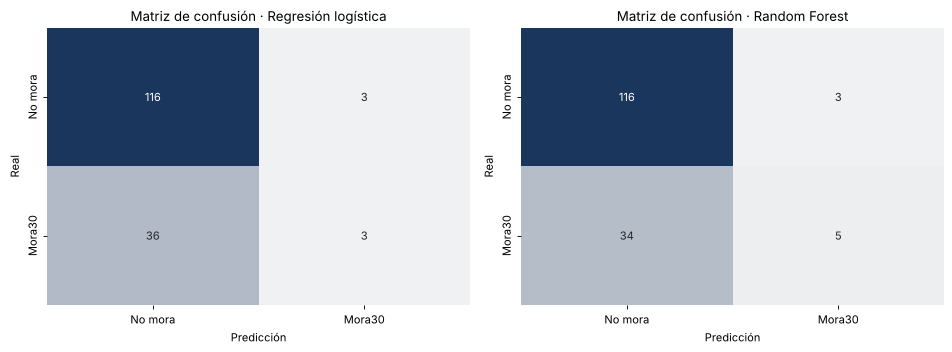

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
etiquetas = ["No mora", "Mora30"]

for ax, (nombre, pred) in zip(axes, [("Regresión logística", pred_simple), ("Random Forest", pred_rf)]):
    mc = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(mc, annot=True, fmt="d", cmap=sns.light_palette(paleta_consultora[0], as_cmap=True),
                xticklabels=etiquetas, yticklabels=etiquetas, cbar=False, ax=ax)
    ax.set_title(f"Matriz de confusión · {nombre}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")

    tn, fp, fn, tp = mc.ravel()
    print(f"{nombre}:")
    print(f"  Morosos detectados (VP): {tp} | Morosos NO detectados (FN): {fn}")
    print(f"  Buenos clientes marcados como riesgo (FP): {fp} | Buenos bien clasificados (VN): {tn}\n")

plt.tight_layout()
plt.show()

### 4.1 (Complementario) Modelos con clases balanceadas

Solo ≈26 % de los clientes cae en mora, así que los modelos tienden a predecir "no mora" para casi todos (alta exactitud, pero recall bajo). Para un banco es más costoso **no detectar** a un moroso que revisar de más a un buen cliente. Con `class_weight="balanced"` se le da más peso a los casos de mora durante el entrenamiento. Se usa la misma separación de datos.

In [41]:
modelo_simple_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
)
modelo_simple_bal.fit(X_train, y_train)

modelo_rf_bal = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                                       class_weight="balanced", min_samples_leaf=5)
modelo_rf_bal.fit(X_train, y_train)

tabla_balanceada = pd.DataFrame([
    evaluar("Regresión logística (balanceada)", y_test,
            modelo_simple_bal.predict(X_test), modelo_simple_bal.predict_proba(X_test)[:, 1]),
    evaluar("Random Forest (balanceado)", y_test,
            modelo_rf_bal.predict(X_test), modelo_rf_bal.predict_proba(X_test)[:, 1]),
]).set_index("Modelo").round(3)

display(pd.concat([tabla_metricas.drop(columns="Supera línea base (exactitud)"), tabla_balanceada]))

,Exactitud,Precisión,Recall,F1,AUC
Modelo,,,,,
Línea base (clase más común),0.753,0.000,0.000,0.000,0.500
Regresión logística,0.753,0.500,0.077,0.133,0.609
Random Forest,0.766,0.625,0.128,0.213,0.638
Regresión logística (balanceada),0.582,0.315,0.590,0.411,0.600
Random Forest (balanceado),0.677,0.350,0.359,0.354,0.572


### Resumen automático para redactar el análisis

Esta celda imprime los números clave que se usan en el análisis de la sección 5.

In [42]:
mejor_f1 = tabla_metricas.drop(index="Línea base (clase más común)")["F1"].idxmax()
mejor_recall = tabla_metricas.drop(index="Línea base (clase más común)")["Recall"].idxmax()

print(f"Línea base (exactitud): {linea_base:.1%}")
for m in ["Regresión logística", "Random Forest"]:
    fila = tabla_metricas.loc[m]
    print(f"{m}: exactitud {fila['Exactitud']:.1%} | precisión {fila['Precisión']:.1%} | "
          f"recall {fila['Recall']:.1%} | F1 {fila['F1']:.3f} | AUC {fila['AUC']:.3f}")
print(f"\nMejor F1: {mejor_f1} | Mejor recall: {mejor_recall}")
print("\nTop 5 variables Random Forest:", list(top10.index[:5]))
print("Top 5 coeficientes logística:", [f"{k} ({v:+.2f})" for k, v in top_coef.head(5).items()])
for m in tabla_balanceada.index:
    fila = tabla_balanceada.loc[m]
    print(f"{m}: exactitud {fila['Exactitud']:.1%} | recall {fila['Recall']:.1%} | F1 {fila['F1']:.3f}")
total_morosos = int(y_test.sum())
print(f"\nClientes en mora en el set de prueba: {total_morosos} de {len(y_test)}")

Línea base (exactitud): 75.4%
Regresión logística: exactitud 75.3% | precisión 50.0% | recall 7.7% | F1 0.133 | AUC 0.609
Random Forest: exactitud 76.6% | precisión 62.5% | recall 12.8% | F1 0.213 | AUC 0.638

Mejor F1: Random Forest | Mejor recall: Random Forest

Top 5 variables Random Forest: ['%deuda_actual_sistema_financiero', 'calificacionsistema_financiero', 'ingresos', 'gastos', 'edad']
Top 5 coeficientes logística: ['ingresos (-1.05)', 'gastos (-0.44)', 'tipo_vivienda_FAMILIAR (+0.42)', 'nivel_academico_ESPECIALIZACIÓN (-0.35)', 'calificacion_superfinanciera_E (-0.32)']
Regresión logística (balanceada): exactitud 58.2% | recall 59.0% | F1 0.411
Random Forest (balanceado): exactitud 67.7% | recall 35.9% | F1 0.354

Clientes en mora en el set de prueba: 39 de 158


## 5. Análisis

1. **¿Cuál modelo funciona mejor?** Decir siempre "no mora" acierta el 75,3 % de los casos sin detectar a ningún moroso. La regresión logística queda en 75,3 % de exactitud (no supera la línea base) y el Random Forest en 76,6 %: es el mejor de los dos (F1 0,21 vs 0,13; AUC 0,64 vs 0,61), pero solo detecta 5 de los 39 morosos del set de prueba (recall 12,8 %). Con clases balanceadas (4.1) la regresión logística detecta 23 de 39 (recall 59 %) y logra el mejor F1 de todas las variantes (0,41), a cambio de bajar la exactitud a 58 %.
2. **¿Qué variables influyen más?** En el Random Forest pesan el % de deuda en el sistema financiero, el score de la central de riesgo, los ingresos, los gastos y la edad; la regresión logística indica que más ingresos, experiencia financiera y antigüedad en el sistema reducen el riesgo. Tiene sentido para un banco: capacidad de pago, endeudamiento e historial explican la mora, y coincide con el EDA (sin experiencia financiera la mora es 28,9 % vs 21,4 %).
3. **¿Qué modelo recomendamos?** La ventaja del Random Forest es pequeña (1,3 puntos de exactitud y 0,03 de AUC) y deja pasar casi todos los morosos. Recomendamos la **regresión logística con clases balanceadas**: es fácil de explicar al comité de riesgo y al regulador (cada coeficiente dice si una variable sube o baja el riesgo) y es la que más morosos detecta. Ningún modelo es lo bastante preciso para aprobar o rechazar créditos de forma automática: con solo datos financieros la respuesta a la pregunta del proyecto es "sí, pero de forma limitada".
4. **Acción concreta:** usar la probabilidad de la regresión logística como alerta temprana en el desembolso: los clientes marcados pasan a verificación de ingresos y deuda, reciben un cupo inicial reducido y entran a cobranza preventiva. En paralelo, corregir la calidad de la base (registros gemelos, scores con ".", `moramaxima_12_meses` que define la mora) y sumar variables de comportamiento de pago para que el modelo mejore.